# Pequeña fábrica con averías: el modelo de TCT_Proyect y su programa para OpenPLC

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nebisman/deslab-py3/blob/main/notebooks/factory_io/LCS_modular_control_small_factory_openplc.ipynb)

La escena es la pequeña fábrica de Factory I/O (`Small_Factory.factoryio`, en la carpeta
`Factory scenes`). Una cinta de alimentación lleva piezas a la máquina $M_1$, un centro de
mecanizado. Cuando $M_1$ termina, un emisor pone la pieza en la cinta del buffer, que la lleva
hasta una cuchilla de tope frente a la máquina $M_2$. En el tablero están el pulsador de arranque
y, para cada máquina, un pulsador que simula la avería y otro que ordena la reparación.

Este notebook es la versión DESlab del script `Small_factory.py` de TCT_Proyect, que usaba TCT:
tiene los mismos autómatas, especificaciones y mapa de señales, definidos directamente con `fsa`
y solo con los autolazos que hacen falta. `generate_ST_OPENPLC` genera el programa en texto
estructurado (ST) para OpenPLC, y el programa es igual, byte por byte, al `Small_factory.st` que
genera TCT con ese script.

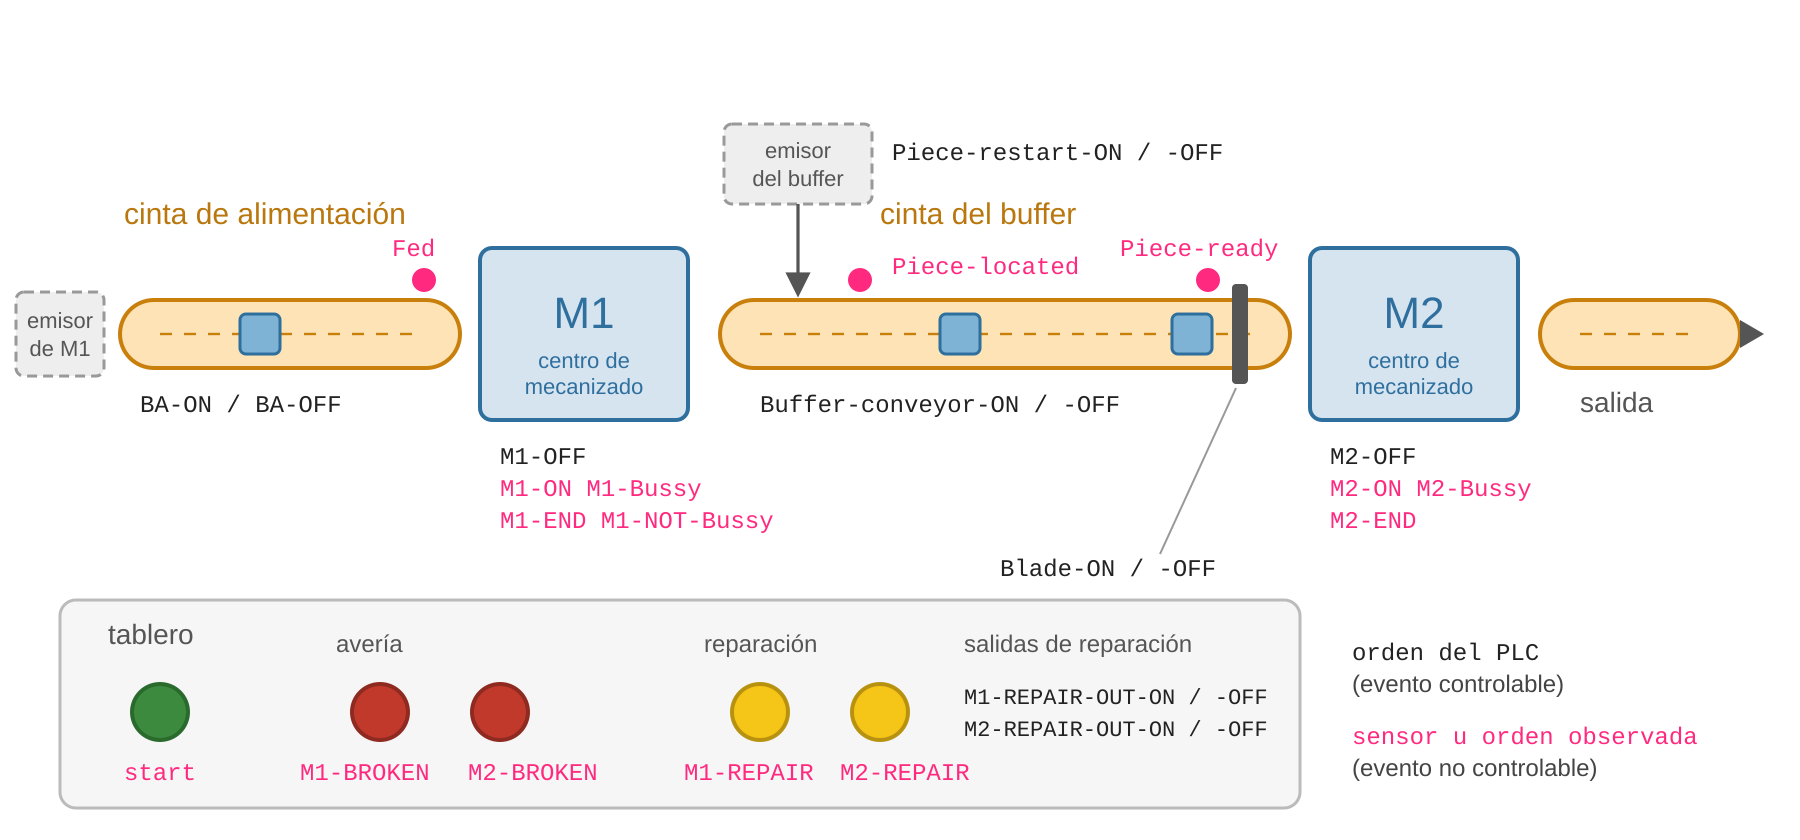

In [ ]:
#@title Instalación de DESlab desde GitHub (ejecute esta celda primero)
import importlib, json, shutil, subprocess, sys
from importlib.metadata import distribution

# programas de graphviz (Colab normalmente ya los trae instalados)
if shutil.which("dot") is None:
    subprocess.run("apt-get -qq install -y graphviz > /dev/null", shell=True)

%pip install -q networkx graphviz
# se reinstala siempre la última versión de DESlab que está en GitHub
%pip install -q --force-reinstall --no-deps --no-cache-dir git+https://github.com/nebisman/deslab-py3.git

# si la celda se ejecuta de nuevo, DESlab se descarga de la memoria para
# que la siguiente celda importe la versión recién instalada
importlib.invalidate_caches()
for name in [m for m in sys.modules if m == "deslab" or m.startswith("deslab.")]:
    del sys.modules[name]

info = json.loads(distribution("deslab").read_text("direct_url.json") or "{}")
print("DESlab instalado desde el commit", info.get("vcs_info", {}).get("commit_id", "?")[:7])

In [2]:
from deslab import *

## 1. Eventos

Se conservan los nombres del script original (incluido `Bussy`), con guiones en lugar de `_`:
DESlab dibuja lo que sigue a `_` como subíndice. `11` y `21` son los nombres que el script da a las
peticiones del supervisor para arrancar $M_1$ y $M_2$.

| Parte | Controlables | No controlables |
|---|---|---|
| máquina $M_1$ | `M1-OFF` (apagar la orden de arranque) | `M1-ON` (la orden de arranque está encendida), `M1-Bussy` (ocupada), `M1-END` (terminó), `M1-NOT-Bussy` (desocupada) |
| máquina $M_2$ | `M2-OFF` | `M2-ON`, `M2-Bussy`, `M2-END` |
| cinta de alimentación | `BA-ON`, `BA-OFF` | `Fed` (la pieza pasó el sensor de entrada de $M_1$) |
| emisor del buffer | `Piece-restart-ON`, `Piece-restart-OFF` | `Piece-located` (pieza al inicio del buffer) |
| cinta del buffer | `Buffer-conveyor-ON`, `Buffer-conveyor-OFF` | `Piece-ready` (pieza en la cuchilla) |
| cuchilla de tope | `Blade-ON`, `Blade-OFF` | |
| averías y reparación | `M1-REPAIR-OUT-ON`, `M1-REPAIR-OUT-OFF`, `R1-PERMITTED`, `R1-NOT-PERMITTED` y los de $M_2$ | `M1-BROKEN` (avería), `M1-REPAIR` (pulsador de reparación) y los de $M_2$ |
| tablero | | `start` (pulsador de arranque) |
| peticiones del supervisor | `11` (arrancar $M_1$), `21` (arrancar $M_2$) | |

`M1-ON` y `M2-ON` no son controlables: la orden de arranque la enciende la petición del
supervisor (sección 5) y los autómatas de las máquinas solo observan que está encendida.

TCT numeraba los eventos controlables con números impares y los no controlables con pares, en el
orden en que el script los declara. Las listas siguen ese orden, que se usa al final para escribir
el programa como TCT.

In [3]:
# en el orden en que Small_factory.py declara los eventos
CONTROLABLES = ['M1-OFF', 'Buffer-conveyor-ON', 'Buffer-conveyor-OFF', 'Blade-OFF', 'Blade-ON',
                'Piece-restart-ON', 'Piece-restart-OFF', 'M2-OFF', 'BA-ON', 'BA-OFF', '11', '21',
                'M1-REPAIR-OUT-ON', 'M2-REPAIR-OUT-ON', 'R1-PERMITTED', 'R1-NOT-PERMITTED',
                'M1-REPAIR-OUT-OFF', 'R2-PERMITTED', 'R2-NOT-PERMITTED', 'M2-REPAIR-OUT-OFF']
NO_CONTROLABLES = ['M1-ON', 'M1-Bussy', 'M1-END', 'start', 'Piece-ready', 'M2-END', 'Piece-located',
                   'M1-BROKEN', 'M2-ON', 'M2-Bussy', 'Fed', 'M1-NOT-Bussy', 'M2-BROKEN',
                   'M1-REPAIR', 'M2-REPAIR']

## 2. El supervisor principal

**Planta.** `model_M1` y `model_M2` son modelos abstractos de las máquinas, con los estados 0
(libre), 1 (trabajando) y 2 (averiada); solo el estado 0 es marcado. La petición `11` pone a
trabajar a $M_1$; vuelve a estar libre cuando su pieza llega al buffer (`Piece-located`) o, si se
avería (`M1-BROKEN`), cuando queda desocupada (`M1-NOT-Bussy`). $M_2$ trabaja con `21` y queda
libre con `M2-END`, también después de una avería (`M2-BROKEN`).

**Especificaciones.**

| Especificación | Qué pide |
|---|---|
| `REQ_Buffer` | el buffer guarda a lo sumo dos piezas: cada `Piece-located` agrega una y cada `21` la retira |
| `REQ_start` | no hay peticiones `11` ni `21` antes del pulsador `start` |
| `REQ_repair` | después de una avería de $M_2$, no se repara $M_1$ antes que $M_2$ |

**Autolazos.** El pulsador `start` lo usa `REQ_start`, así que tiene que estar en la planta como
evento no controlable. `model_M1` lo lleva como autolazo en sus tres estados: la planta no
restringe cuándo se pulsa. Sin él, la planta nunca genera `start` y el supervisor no sale de su
estado inicial. En las especificaciones, un evento no controlable del alfabeto que no está
definido en un estado queda prohibido allí; si la planta puede generarlo, el supervisor tiene que
evitar ese estado. Por eso `REQ_start` lleva el autolazo de `start` en el estado 1 (sin él, el
supervisor queda vacío: el pulsador se puede volver a pulsar) y `REQ_repair` el de `M2-BROKEN` en
el estado 1 ($M_2$ se puede volver a averiar, y la especificación ya no sale de ese estado, como
se explica a continuación).

**Los eventos de reparación en `REQ_repair`.** `M1-REPAIR-OUT-ON` y `M2-REPAIR-OUT-ON` no son
eventos de la planta `model_M1` $\parallel$ `model_M2`. Igual que en TCT, el supervisor no los
genera: después de la primera avería de $M_2$ la especificación queda en su estado 1. Por eso
`REQ_repair` no cambia lo que el supervisor permite; solo duplica sus estados (36 en lugar de 22).
Se conserva para que el programa sea el de TCT. La prioridad de reparación la impone el autómata
auxiliar `repair` de la sección 4.

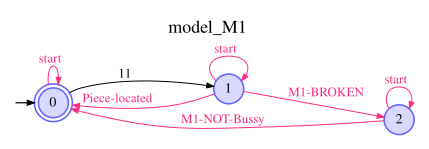

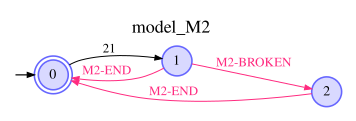

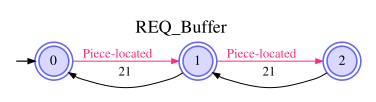

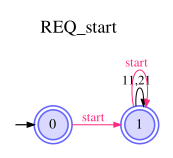

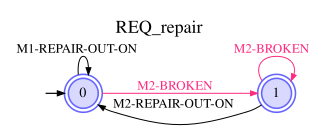

In [4]:
model_M1 = fsa([0, 1, 2], ['11', 'Piece-located', 'M1-BROKEN', 'M1-NOT-Bussy', 'start'],
               [(0, '11', 1), (1, 'Piece-located', 0), (1, 'M1-BROKEN', 2), (2, 'M1-NOT-Bussy', 0),
                (0, 'start', 0), (1, 'start', 1), (2, 'start', 2)],
               [0], [0], Sigcon=['11'], name='model_M1')
model_M2 = fsa([0, 1, 2], ['21', 'M2-END', 'M2-BROKEN'],
               [(0, '21', 1), (1, 'M2-END', 0), (1, 'M2-BROKEN', 2), (2, 'M2-END', 0)],
               [0], [0], Sigcon=['21'], name='model_M2')

REQ_Buffer = fsa([0, 1, 2], ['Piece-located', '21'],
                 [(0, 'Piece-located', 1), (1, '21', 0), (1, 'Piece-located', 2), (2, '21', 1)],
                 [0], [0, 1, 2], Sigcon=['21'], name='REQ_Buffer')
REQ_start = fsa([0, 1], ['start', '11', '21'],
                [(0, 'start', 1), (1, '11', 1), (1, '21', 1),
                 (1, 'start', 1)],
                [0], [0, 1], Sigcon=['11', '21'], name='REQ_start')
REQ_repair = fsa([0, 1], ['M1-REPAIR-OUT-ON', 'M2-BROKEN', 'M2-REPAIR-OUT-ON'],
                 [(0, 'M1-REPAIR-OUT-ON', 0), (0, 'M2-BROKEN', 1), (1, 'M2-REPAIR-OUT-ON', 0),
                  (1, 'M2-BROKEN', 1)],
                 [0], [0, 1], Sigcon=['M1-REPAIR-OUT-ON', 'M2-REPAIR-OUT-ON'], name='REQ_repair')
draw(model_M1, model_M2, REQ_Buffer, REQ_start, REQ_repair)

El supervisor es `supcontrollable(H, G)` con $G$ = `model_M1` $\parallel$ `model_M2` y $H = G \parallel$
`REQ_Buffer` $\parallel$ `REQ_start` $\parallel$ `REQ_repair`. En TCT la especificación se sincronizaba
también con `ALL` (todos los eventos de la planta); en DESlab no hace falta, porque la composición
paralela deja libres los eventos de la planta que la especificación no tiene. El supervisor tiene
36 estados y 119 transiciones, los mismos que calculaba TCT.

In [5]:
G = model_M1 // model_M2
H = G // REQ_Buffer // REQ_start // REQ_repair
SUP = supcontrollable(H, G).setpar(name='$SUP$', style='rectangle')
assert iscontrollable(SUP, G)

usados = {e for x in SUP.X for e in SUP.Gamma(x)}
print('SUP:', len(SUP), 'estados,', sum(len(SUP.Gamma(x)) for x in SUP.X), 'transiciones')
print('eventos de SUP que no aparecen en sus transiciones:', sorted(SUP.Sigma - usados))

SUP: 36 estados, 119 transiciones
eventos de SUP que no aparecen en sus transiciones: ['M1-REPAIR-OUT-ON', 'M2-REPAIR-OUT-ON']


## 3. La alimentación de $M_1$

`B_A` es la cinta de alimentación: se enciende (`BA-ON`), la pieza pasa el sensor de entrada de
$M_1$ (`Fed`), se apaga (`BA-OFF`) y espera a que $M_1$ termine (`M1-END`) para traer la siguiente.
Mientras está encendida, una máscara (sección 5) enciende también el emisor que crea las piezas.
La especificación `start` solo deja encender la cinta después del pulsador de arranque.

Como en la sección 2, `start` es un evento no controlable de la especificación: `B_A` lo lleva como
autolazo en todos sus estados y la especificación `start` en su estado 1. El supervisor `sup_BA`
no va en la lista de supervisores del programa sino entre los autómatas auxiliares de la sección
4, igual que en el script. Tiene 5 estados y 9 transiciones, como el que calculaba TCT.

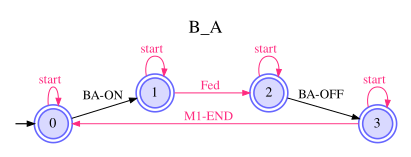

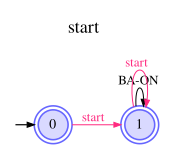

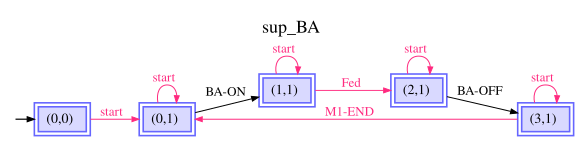

In [6]:
B_A = fsa([0, 1, 2, 3], ['BA-ON', 'Fed', 'BA-OFF', 'M1-END', 'start'],
          [(0, 'BA-ON', 1), (1, 'Fed', 2), (2, 'BA-OFF', 3), (3, 'M1-END', 0),
           (0, 'start', 0), (1, 'start', 1), (2, 'start', 2), (3, 'start', 3)],
          [0], [0, 1, 2, 3], Sigcon=['BA-ON', 'BA-OFF'], name='B_A')
start = fsa([0, 1], ['start', 'BA-ON'],
            [(0, 'start', 1), (1, 'BA-ON', 1),
             (1, 'start', 1)],
            [0], [0, 1], Sigcon=['BA-ON'], name='start')
sup_BA = supcontrollable(B_A // start, B_A).setpar(name='sup_BA', style='rectangle')
draw(B_A, start, sup_BA)

## 4. Autómatas auxiliares

Los autómatas auxiliares van en `Isolated[0]` de `generate_ST_OPENPLC`: cada uno tiene su propio
estado en el programa, escribe las salidas de sus eventos controlables y avanza con sus eventos no
controlables, pero no participa en la síntesis.

| Autómata | Qué hace |
|---|---|
| `M1`, `M2` | cuando la máquina confirma el arranque (`Mi-Bussy`), apaga la orden (`Mi-OFF`) y espera el fin (`Mi-END`) |
| `sup_BA` | el supervisor de la alimentación (sección 3) |
| `generate` | cuando $M_1$ termina, enciende el emisor del buffer (`Piece-restart-ON`) hasta que la pieza llega al sensor (`Piece-located`); si $M_1$ se avería, no hay pieza |
| `Buffer_fill` | mueve la cinta del buffer: lleva la primera pieza hasta la cuchilla (`Piece-ready`) y avanza cada pieza nueva más allá del sensor de entrada (`Piece-located`); cuando $M_2$ termina (`M2-END`), vuelve a avanzar |
| `Blade` | cuando $M_2$ termina, baja la cuchilla (`Blade-OFF`) hasta que pasa la pieza (`Piece-ready`) y la vuelve a subir |
| `repair` | cuando una máquina se avería, permite su reparación (`Ri-PERMITTED`), espera el pulsador (`Mi-REPAIR`), enciende la salida de reparación hasta que la máquina queda libre y la apaga; si $M_2$ se avería mientras $M_1$ espera, primero se repara $M_2$ |

El script de TCT ponía además autolazos de `M1-ON`, `M1-Bussy` y `M1-END` en `M1`. No hacen falta:
el programa de un autómata auxiliar solo usa sus transiciones entre estados distintos y sus
eventos controlables. Las marcas tampoco intervienen; se conservan las del script (en `Blade` y
`generate`, ninguna).

Las transiciones de `generate`, `Buffer_fill` y `repair` se guardan en listas aparte porque el
generador las necesita en ese orden (sección 6).

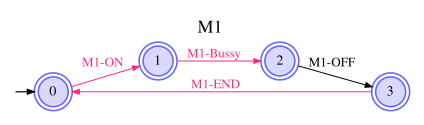

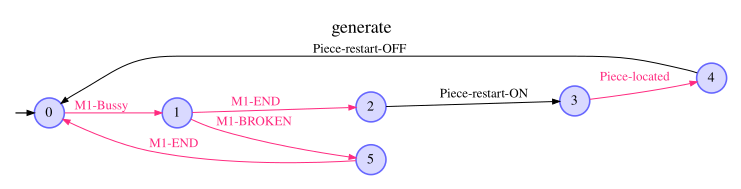

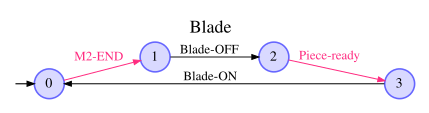

In [7]:
M1 = fsa([0, 1, 2, 3], ['M1-ON', 'M1-Bussy', 'M1-OFF', 'M1-END'],
         [(0, 'M1-ON', 1), (1, 'M1-Bussy', 2), (2, 'M1-OFF', 3), (3, 'M1-END', 0)],
         [0], [0, 1, 2, 3], Sigcon=['M1-OFF'], name='M1')
M2 = fsa([0, 1, 2, 3], ['M2-ON', 'M2-Bussy', 'M2-OFF', 'M2-END'],
         [(0, 'M2-ON', 1), (1, 'M2-Bussy', 2), (2, 'M2-OFF', 3), (3, 'M2-END', 0)],
         [0], [0, 1, 2, 3], Sigcon=['M2-OFF'], name='M2')

T_generate = [(0, 'M1-Bussy', 1), (1, 'M1-END', 2), (2, 'Piece-restart-ON', 3), (3, 'Piece-located', 4),
              (4, 'Piece-restart-OFF', 0), (1, 'M1-BROKEN', 5), (5, 'M1-END', 0)]
generate = fsa(list(range(6)), {e for _, e, _ in T_generate}, T_generate, [0], [],
               Sigcon=['Piece-restart-ON', 'Piece-restart-OFF'], name='generate')

T_buffer_fill = [(0, 'start', 1), (1, 'M1-END', 2), (2, 'Buffer-conveyor-ON', 3), (3, 'Piece-ready', 4),
                 (4, 'Buffer-conveyor-OFF', 5), (5, 'M2-END', 2), (7, 'M2-END', 2), (5, 'M1-END', 6),
                 (6, 'Buffer-conveyor-ON', 7), (7, 'Piece-located', 8), (8, 'Buffer-conveyor-OFF', 5),
                 (1, 'M1-BROKEN', 9), (9, 'M1-END', 1)]
Buffer_fill = fsa(list(range(10)), {e for _, e, _ in T_buffer_fill}, T_buffer_fill, [0], list(range(10)),
                  Sigcon=['Buffer-conveyor-ON', 'Buffer-conveyor-OFF'], name='Buffer_fill')

Blade = fsa([0, 1, 2, 3], ['M2-END', 'Blade-OFF', 'Piece-ready', 'Blade-ON'],
            [(0, 'M2-END', 1), (1, 'Blade-OFF', 2), (2, 'Piece-ready', 3), (3, 'Blade-ON', 0)],
            [0], [], Sigcon=['Blade-OFF', 'Blade-ON'], name='Blade')

T_repair = [(0, 'M1-BROKEN', 1), (1, 'R1-PERMITTED', 2), (2, 'M1-REPAIR', 3),
            (3, 'M1-REPAIR-OUT-ON', 4), (4, 'R1-NOT-PERMITTED', 5), (5, 'M1-NOT-Bussy', 6),
            (6, 'M1-REPAIR-OUT-OFF', 0),
            (0, 'M2-BROKEN', 7), (7, 'R2-PERMITTED', 8), (8, 'M2-REPAIR', 9),
            (9, 'M2-REPAIR-OUT-ON', 10), (10, 'R2-NOT-PERMITTED', 11), (11, 'M2-END', 12),
            (12, 'M2-REPAIR-OUT-OFF', 0),
            # M2 se avería mientras M1 espera su reparación: primero se repara M2
            (2, 'M2-BROKEN', 13), (13, 'R1-NOT-PERMITTED', 14), (14, 'R2-PERMITTED', 15),
            (15, 'M2-REPAIR', 16), (16, 'M2-REPAIR-OUT-ON', 17), (17, 'R2-NOT-PERMITTED', 18),
            (18, 'M2-END', 19), (19, 'M2-REPAIR-OUT-OFF', 1),
            # M1 se avería mientras M2 espera la suya
            (8, 'M1-BROKEN', 15)]
repair = fsa(list(range(20)), {e for _, e, _ in T_repair}, T_repair, [0], list(range(20)),
             Sigcon=['R1-PERMITTED', 'M1-REPAIR-OUT-ON', 'R1-NOT-PERMITTED', 'M1-REPAIR-OUT-OFF',
                     'R2-PERMITTED', 'M2-REPAIR-OUT-ON', 'R2-NOT-PERMITTED', 'M2-REPAIR-OUT-OFF'],
             name='repair')

auxiliares = [M1, M2, sup_BA, generate, Buffer_fill, Blade, repair]
draw(M1, generate, Blade)

## 5. Mapa de señales

Es el mapa del script original, en el mismo orden: el orden de las declaraciones del programa sale
de él. Las claves son los eventos, con guiones; las variables del PLC conservan `_` porque en ST un
identificador no puede tener guiones.

| Formato | Significado | Ejemplo |
|---|---|---|
| `Variable:ON:dirección`, `Variable:OFF[:dirección]` | escribe 1 o 0 en una salida; en una entrada, observa el nivel 1 o 0 | `'M1-ON': 'GD_OUT_0:ON:%QX100.0'`, `'M1-BROKEN': 'GD_IN_10:OFF:%IX101.0'` |
| `FE_Nombre:Entrada:dirección` | flanco de bajada de una entrada (`F_TRIG`) | `'M1-END': 'FE_M1E:GD_IN_0:%IX100.0'` |
| `INTERN_k:ON`, `INTERN_k:OFF` | variable interna del programa | `'11': 'INTERN_0:ON'` |

Las averías son entradas que pasan a 0 (`GD_IN_10:OFF`, pulsadores normalmente cerrados). Las
peticiones `11` y `21` son variables internas: las **parejas** de `Isolated[1]` las convierten en
órdenes. La pareja `('11', 'M1-ON')` pone `GD_OUT_0 = 1` cuando sube `INTERN_0` y, con la orden ya
encendida, borra la petición; el autómata auxiliar `M1` apaga la orden después.

`Buffer-conveyor-ON-UC`, `M1-REPAIR-DONE` y `M2-REPAIR-DONE` no son eventos de ningún autómata,
pero están en el script; los dos últimos declaran las variables `INTERN_4` e `INTERN_5` del
programa. `Mask` copia en
cada scan una señal en otras salidas: la cinta de alimentación (`GD_OUT_2`) también enciende
`GD_OUT_3` (el emisor de $M_1$), y cada avería (`NOT GD_IN_10`, `NOT GD_IN_11`) enciende
`GD_OUT_8` o `GD_OUT_9`.

In [8]:
actuators = {
    'M1-ON': 'GD_OUT_0:ON:%QX100.0', 'M1-OFF': 'GD_OUT_0:OFF',
    'M2-ON': 'GD_OUT_1:ON:%QX100.1', 'M2-OFF': 'GD_OUT_1:OFF',
    'M1-Bussy': 'GD_IN_0:ON:%IX100.0', 'M1-NOT-Bussy': 'GD_IN_0:OFF:%IX100.0',
    'M2-Bussy': 'GD_IN_1:ON:%IX100.1',
    'M1-END': 'FE_M1E:GD_IN_0:%IX100.0', 'M2-END': 'FE_M2E:GD_IN_1:%IX100.1',
    'start': 'GD_IN_15:ON:%IX100.5',
    'BA-ON': 'GD_OUT_2:ON:%QX100.2', 'BA-OFF': 'GD_OUT_2:OFF',
    'Fed': 'FE_A:GD_IN_2:%IX100.2',
    'Buffer-conveyor-ON': 'GD_OUT_4:ON:%QX100.4', 'Buffer-conveyor-ON-UC': 'GD_OUT_4:ON:%QX100.4',
    'Buffer-conveyor-OFF': 'GD_OUT_4:OFF',
    'Piece-located': 'FE_PL:GD_IN_3:%IX100.3', 'Piece-ready': 'FE_PR:GD_IN_4:%IX100.4',
    'Piece-restart-ON': 'GD_OUT_5:ON:%QX100.5', 'Piece-restart-OFF': 'GD_OUT_5:OFF:%QX100.5',
    'Blade-ON': 'GD_OUT_6:ON:%QX100.6', 'Blade-OFF': 'GD_OUT_6:OFF:%QX100.6',
    'M1-BROKEN': 'GD_IN_10:OFF:%IX101.0', 'M2-BROKEN': 'GD_IN_11:OFF:%IX101.1',
    'M1-REPAIR': 'GD_IN_12:ON:%IX101.2', 'M2-REPAIR': 'GD_IN_13:ON:%IX101.3',
    'M1-REPAIR-DONE': 'INTERN_4:OFF', 'M2-REPAIR-DONE': 'INTERN_5:OFF',
    'M1-REPAIR-OUT-ON': 'GD_OUT_10:ON:%QX101.2', 'M2-REPAIR-OUT-ON': 'GD_OUT_11:ON:%QX101.3',
    'M1-REPAIR-OUT-OFF': 'GD_OUT_10:OFF:%QX101.2', 'M2-REPAIR-OUT-OFF': 'GD_OUT_11:OFF:%QX101.3',
    'R1-PERMITTED': 'INTERN_2:ON', 'R2-PERMITTED': 'INTERN_3:ON',
    'R1-NOT-PERMITTED': 'INTERN_2:OFF', 'R2-NOT-PERMITTED': 'INTERN_3:OFF',
    '11': 'INTERN_0:ON', '21': 'INTERN_1:ON',
}
Mask = {'GD_OUT_2': [('GD_OUT_3', '%QX100.3')],
        'NOT GD_IN_10': [('GD_OUT_8', '%QX101.0')],
        'NOT GD_IN_11': [('GD_OUT_9', '%QX101.1')]}
parejas = [('21', 'M2-ON'), ('11', 'M1-ON')]

## 6. Generar el programa

| Parámetro | Valor |
|---|---|
| `supervisors`, `plants` | `[SUP]` y `[G]`: la planta da la clasificación de los eventos del supervisor |
| `Isolated` | `[auxiliares, parejas]` |
| `initial` | `'start'`: el programa espera el pulsador de arranque antes de empezar |
| `event_order` | los eventos ordenados por el número que les daba TCT |
| `state_order` | numeración de los estados de `SUP`, `generate`, `Buffer_fill` y `repair` |
| `transition_order` | orden de las transiciones de `generate`, `Buffer_fill` y `repair` |

Por omisión, `generate_ST_OPENPLC` numera los estados de cada autómata en el orden de una búsqueda
en anchura desde el estado inicial y escribe las transiciones de cada estado en el orden de
`event_order`. TCT numeraba de otra forma:

* los estados de un supervisor, en el orden en que aparecen en el producto $H = G \parallel E$ del
  que se sintetizó: `state_order={SUP: H}` le pide al generador recorrer $H$ en anchura y numerar
  los estados de `SUP` en ese orden;
* los estados de un autómata auxiliar, con los números con que se definió, y sus transiciones en el
  orden en que se declararon: `state_order={generate: range(6), ...}` y
  `transition_order={generate: T_generate, ...}`.

En los demás autómatas las dos numeraciones coinciden, así que no hace falta darlas. En `generate`,
`Buffer_fill` y `repair` no: tienen estados con dos salidas, y la búsqueda en anchura los recorre en
otro orden. Cambiar la numeración solo cambia los números de los estados en el programa; el orden
de las transiciones decide, además, cuál se toma si dos eventos del mismo estado llegan en el mismo
scan. Con los dos, el programa es el mismo de TCT. En la variable `state` del programa, `state[0]` es `SUP` y `state[1]` a
`state[7]` son los auxiliares en el orden de la lista.

In [9]:
import hashlib
from pathlib import Path

codigo = {e: 2 * k + 1 for k, e in enumerate(CONTROLABLES)}
codigo.update({e: 2 * k for k, e in enumerate(NO_CONTROLABLES)})
orden_eventos = sorted(codigo, key=codigo.get)

carpeta = Path('ST_Generated')
st = generate_ST_OPENPLC([SUP], plants=[G], actuators=actuators, namest='Small_factory',
                         Mask=Mask, Isolated=[auxiliares, parejas], initial='start',
                         output_dir=carpeta, event_order=orden_eventos,
                         state_order={SUP: H, generate: range(6), Buffer_fill: range(10),
                                      repair: range(20)},
                         transition_order={generate: T_generate, Buffer_fill: T_buffer_fill,
                                           repair: T_repair})
archivo = carpeta / 'Small_factory.st'
assert archivo.read_text(encoding='utf-8') == st
print('programa guardado en', archivo)
print('líneas:', len(st.splitlines()))

# huella SHA-256 del Small_factory.st que genera TCT con Small_factory.py
TCT = '582689a29b0551e9d76f1f26906075c45b790cdd5defcfc1e97696c72b687b40'
print('¿igual al programa de TCT?', hashlib.sha256(st.encode('utf-8')).hexdigest() == TCT)

programa guardado en ST_Generated/Small_factory.st
líneas: 540
¿igual al programa de TCT? True


In [10]:
print(st)
# en Colab se descarga el archivo; en Jupyter queda un enlace
try:
    from google.colab import files
    files.download(str(archivo))
except ImportError:
    from IPython.display import FileLink, display
    display(FileLink(str(archivo)))

FUNCTION_BLOCK random_number
	VAR_INPUT
		IN : BOOL;
	END_VAR
	VAR
		M : BOOL;
		INIT : BOOL;
	END_VAR
	VAR_OUTPUT
		OUT : DINT;
	END_VAR

	IF INIT = 0 THEN
		{#include <stdio.h>}
		{#include <stdlib.h>}
		IN := 1;
	END_IF;
	IF M = 0 and IN = 1 THEN
		{SetFbVar(OUT,rand())}
	END_IF;
END_FUNCTION_BLOCK
PROGRAM tesis0
	VAR
		random : random_number;
		random_num : DINT;
		initial : BOOL;
		state : ARRAY [0..8] OF DINT;
		slt0 : ARRAY [0..2] OF DINT;
		FE_M1E : F_TRIG;
		FE_M2E : F_TRIG;
		FE_A : F_TRIG;
		FE_PL : F_TRIG;
		FE_PR : F_TRIG;
		INTERN_4 : BOOL;
		INTERN_5 : BOOL;
		INTERN_2 : BOOL;
		INTERN_3 : BOOL;
		INTERN_0 : BOOL;
		INTERN_1 : BOOL;
	END_VAR
	VAR
		GD_OUT_3 AT %QX100.3 : BOOL;
 		GD_OUT_8 AT %QX101.0 : BOOL;
 		GD_OUT_9 AT %QX101.1 : BOOL;
 		GD_OUT_0 AT %QX100.0 : BOOL;
		GD_OUT_1 AT %QX100.1 : BOOL;
		GD_IN_0 AT %IX100.0 : BOOL;
		GD_IN_1 AT %IX100.1 : BOOL;
		GD_IN_15 AT %IX100.5 : BOOL;
		GD_OUT_2 AT %QX100.2 : BOOL;
		GD_IN_2 AT %IX100.2 : BOOL;
		GD_OUT_4 AT %QX100

ST_Generated/Small_factory.st

## 7. Validación y puesta en marcha

El programa generado es idéntico al `Small_factory.st` que genera TCT con `Small_factory.py`: la
celda anterior compara su huella SHA-256. La prueba `tests/test_openplc_notebooks.py` del
repositorio ejecuta las celdas de este notebook y comprueba esa huella, y además que cada autolazo
de las especificaciones es necesario y que cada evento no controlable de una especificación está
en la planta de su supervisor.

Para llevarlo a OpenPLC, importe el archivo `.st`, compílelo y asigne las direcciones de la escena.
Con las máquinas libres y el buffer vacío, pulse el arranque y siga una pieza: entra a $M_1$, pasa
al buffer, la cuchilla la deja pasar cuando $M_2$ termina y $M_2$ la procesa. Después simule una
avería de cada máquina con su pulsador, y luego las dos: la reparación de $M_2$ debe ir primero.